In [1]:
import numpy as np
import cv2 
import glob
import pickle
import matplotlib.pyplot as plt

In [152]:
calibration_folder = 'Z:/distance-coding-project/calibration/camera-calibration'

In [148]:
# Defining the dimensions of checkerboard
CHECKERBOARD = (8,5)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
 
# Creating vector to store vectors of 3D points for each checkerboard image
objpoints = []
# Creating vector to store vectors of 2D points for each checkerboard image
imgpoints = [] 
 
# Defining the world coordinates for 3D points
objp = np.zeros((1, CHECKERBOARD[0] * CHECKERBOARD[1], 3), np.float32)
objp[0,:,:2] = np.mgrid[0:CHECKERBOARD[0], 0:CHECKERBOARD[1]].T.reshape(-1, 2)
prev_img_shape = None
 
# Extracting path of individual image stored in a given directory
images = glob.glob(calibration_folder + '/*.jpg')

for fname in images:

    img = cv2.imread(fname)
    gray = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
    # Find the chess board corners
    # If desired number of corners are found in the image then ret = true
    ret, corners = cv2.findChessboardCorners(gray, CHECKERBOARD, cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_FAST_CHECK + cv2.CALIB_CB_NORMALIZE_IMAGE)
     
    """
    If desired number of corner are detected,
    we refine the pixel coordinates and display 
    them on the images of checker board
    """
    if ret:
        objpoints.append(objp)
        # refining pixel coordinates for given 2d points.
        corners2 = cv2.cornerSubPix(gray, corners, (11,11),(-1,-1), criteria)
         
        imgpoints.append(corners2)
      
        # Draw and display the corners
        img = cv2.drawChessboardCorners(img, CHECKERBOARD, corners2, ret)
        
        cv2.imshow('img',img)
        cv2.waitKey(0)
        cv2.destroyAllWindows()
     
h,w = img.shape[:2]

In [149]:
ret, mtx, dist, rvecs, tvecs = cv2.calibrateCamera(objpoints, imgpoints, gray.shape[::-1], None, None)

Text(0.5, 1.0, 'Undistorted Image')

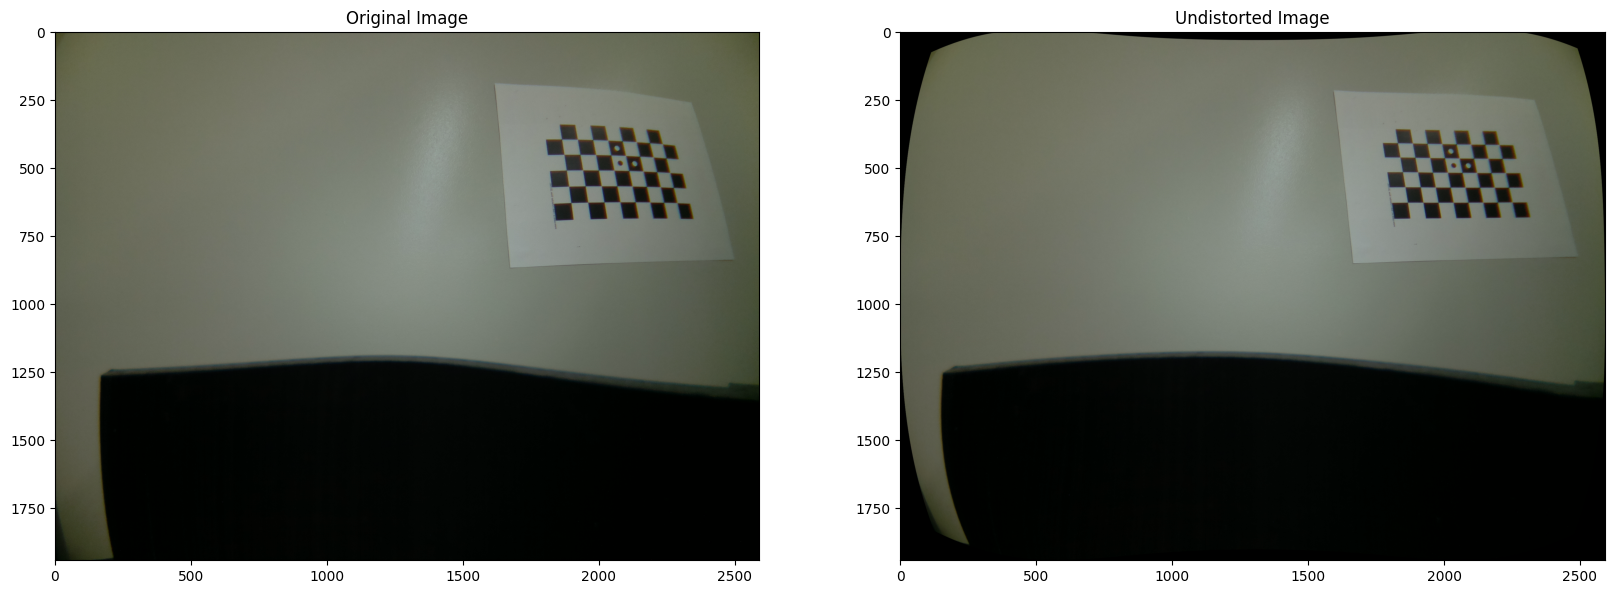

In [145]:
img = cv2.imread(calibration_folder + '/checkerboard-3.jpg')

h,  w = img.shape[:2]
newcameramtx, roi = cv2.getOptimalNewCameraMatrix(mtx, dist, (w,h), 1, (w,h))

# undistort
dst = cv2.undistort(img, mtx, dist, None, newcameramtx)
# crop the image
x, y, w, h = roi
dst = dst

# make a subplot with 1 row and 2 columns
fig, ax = plt.subplots(1, 2, figsize=(20, 10))

# plot the original image
ax[0].imshow(img)
ax[0].set_title('Original Image')

# plot the undistorted image
ax[1].imshow(dst)
ax[1].set_title('Undistorted Image')

True

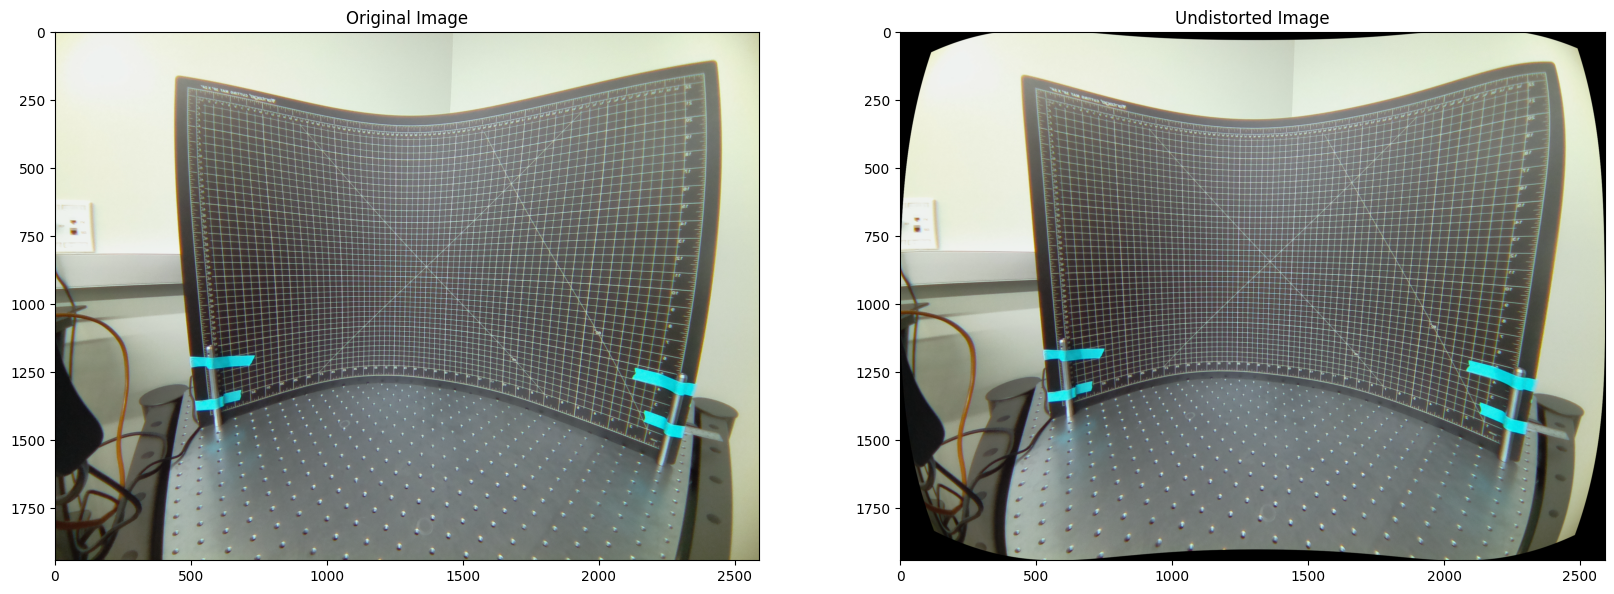

In [231]:
# distance calibration
distance_calibration_folder = 'Z:/distance-coding-project/calibration/240123'

img = cv2.imread(calibration_folder + '/grid-board.jpg')
h,  w = img.shape[:2]
dst = cv2.undistort(img, mtx, dist, None, newcameramtx)

# make a subplot with 1 row and 2 columns
fig, ax = plt.subplots(1, 2, figsize=(20, 10))

# plot the original image
ax[0].imshow(img)
ax[0].set_title('Original Image')

# plot the undistorted image
ax[1].imshow(dst)
ax[1].set_title('Undistorted Image')

# save undistorted image to the same folder
cv2.imwrite(calibration_folder + '/grid-board-undistorted.jpg', dst)


Lines detected


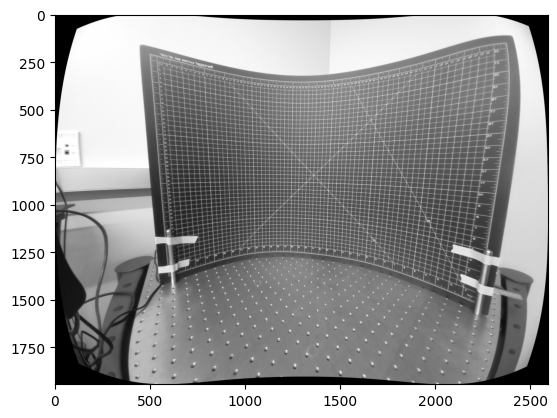

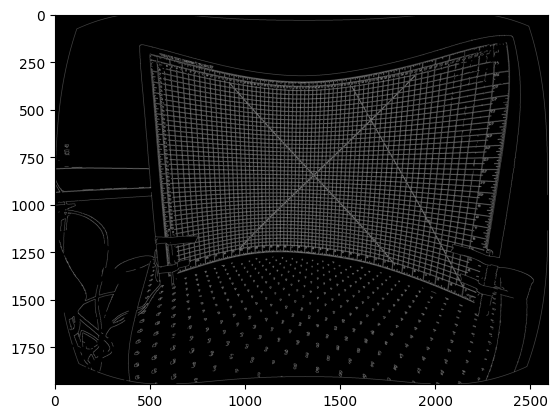

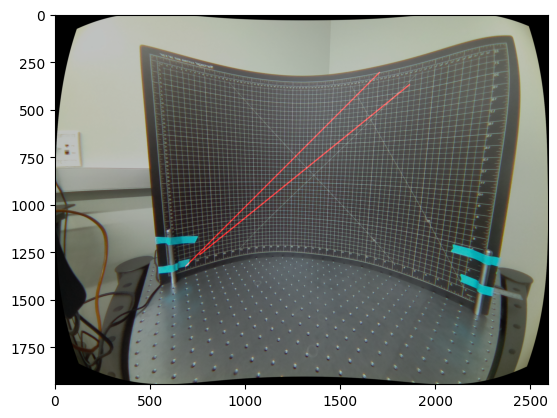

In [232]:
# img = cv2.imread(calibration_folder + '/grid-board.jpg')
# img = img[100:-400, 450:2400]

img = dst
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.medianBlur(gray, 1)

plt.figure()
plt.imshow(blur, cmap='gray')


# adapt_type = cv2.ADAPTIVE_THRESH_GAUSSIAN_C
# thresh_type = cv2.THRESH_BINARY_INV
# bin_img = cv2.adaptiveThreshold(blur, 255, adapt_type, thresh_type, 3, -2)

low_threshold = 100
high_threshold = 150
edges = cv2.Canny(blur, low_threshold, high_threshold)

plt.figure()
plt.imshow(edges, cmap='gray')

rho = 1  # distance resolution in pixels of the Hough grid
theta = np.pi / 180  # angular resolution in radians of the Hough grid
threshold = 15  # minimum number of votes (intersections in Hough grid cell)
min_line_length = 1000  # minimum number of pixels making up a line
max_line_gap = 20  # maximum gap in pixels between connectable line segments
line_image = np.copy(img) * 0  # creating a blank to draw lines on

# Run Hough on edge detected image
# Output "lines" is an array containing endpoints of detected line segments
lines = cv2.HoughLinesP(edges, rho, theta, threshold, np.array([]),
                    min_line_length, max_line_gap)

# is lines empty
if lines is None:
    print('No lines detected')
else:
    print('Lines detected')

for line in lines:
    for x1,y1,x2,y2 in line:
        cv2.line(line_image,(x1,y1),(x2,y2),(255,0,0),5)
        
# Draw the lines on the  image
lines_edges = cv2.addWeighted(img, 0.8, line_image, 1, 0)

plt.figure()
plt.imshow(lines_edges)

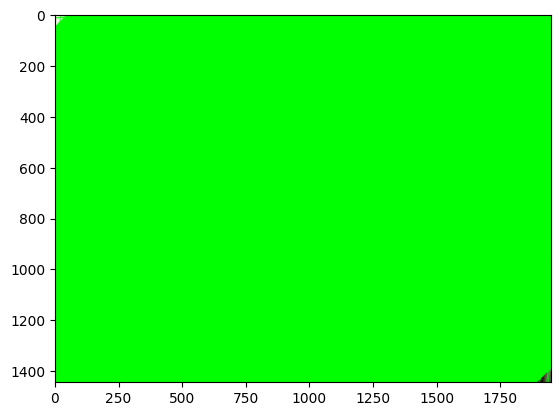

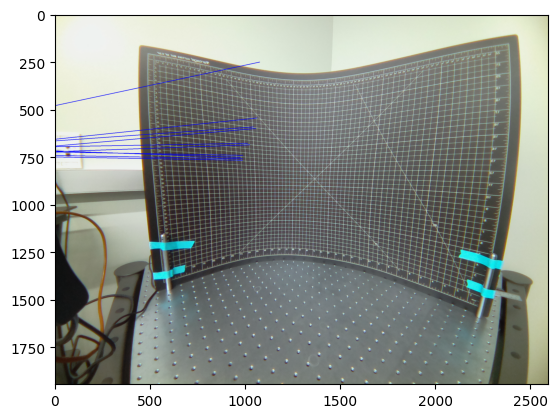

No circles detected in distorted image


Text(0.5, 1.0, 'Undistorted Image')

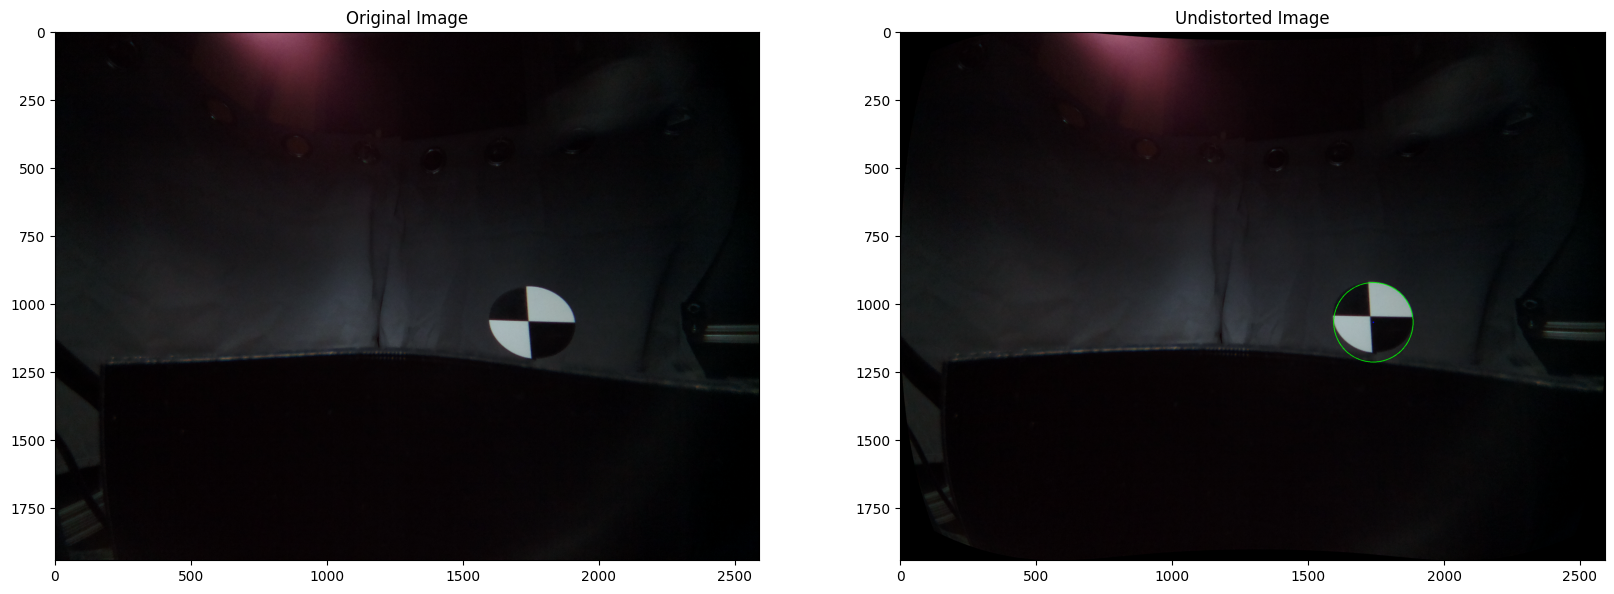

In [147]:
# Convert to grayscale. 

img = cv2.imread(distance_calibration_folder + '/240123_far_0.jpg')
dst = cv2.undistort(img, mtx, dist, None, newcameramtx)

gray_distorted = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) 
gray_undistorted = cv2.cvtColor(dst, cv2.COLOR_BGR2GRAY)
  
# Blur using 3 * 3 kernel. 
gray_blurred = cv2.blur(gray, (3, 3)) 
gray_blurred_undistorted = cv2.blur(gray_undistorted, (3, 3))

dp = 1
minDist = 100
param1 = 50
param2 = 15
minRadius = 140
maxRadius = 150

# Apply Hough transform on the blurred image. 
detected_circles_distorted = cv2.HoughCircles(gray_blurred,  
                   cv2.HOUGH_GRADIENT, dp, minDist, param1 = param1, 
               param2 = param2, minRadius = minRadius, maxRadius = maxRadius)
detected_circles_undistorted = cv2.HoughCircles(gray_blurred_undistorted,  
                   cv2.HOUGH_GRADIENT, dp, minDist, param1 = param1, 
               param2 = param2, minRadius = minRadius, maxRadius = maxRadius)


if detected_circles_distorted is not None:
    circles_distorted = np.uint16(np.around(detected_circles_distorted))
    
    for pt in circles_distorted[0, :]: 
        a, b, r = pt[0], pt[1], pt[2] 

        # Draw the circumference of the circle. 
        cv2.circle(img, (a, b), r, (0, 255, 0), 2) 

        # Draw a small circle (of radius 1) to show the center. 
        cv2.circle(img, (a, b), 1, (0, 0, 255), 3)
else:
    print('No circles detected in distorted image')


if detected_circles_undistorted is not None:
    circles_undistorted = np.uint16(np.around(detected_circles_undistorted))
    
    for pt in circles_undistorted[0, :]: 
        a, b, r = pt[0], pt[1], pt[2] 

        # Draw the circumference of the circle. 
        cv2.circle(dst, (a, b), r, (0, 255, 0), 2) 

        # Draw a small circle (of radius 1) to show the center. 
        cv2.circle(dst, (a, b), 1, (0, 0, 255), 3)
else:
    print('No circles detected in undistorted image')

# make a subplot with 1 row and 2 columns
fig, ax = plt.subplots(1, 2, figsize=(20, 10))

# plot the original image
ax[0].imshow(img)
ax[0].set_title('Original Image')

# plot the undistorted image
ax[1].imshow(dst)
ax[1].set_title('Undistorted Image')
